<a href="https://colab.research.google.com/github/Andrew35780/dap-2024/blob/main/les05/lab.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Лабораторная работа №5. Визуализация данных

In [1]:
import sys
import matplotlib as mpl
import matplotlib.pyplot as plt
import numpy as np

print(f"Python version: {sys.version}")
print(f"Numpy version: {np.version.version}")
print(f"Matplotlib version: {mpl.__version__}")

%matplotlib inline

Python version: 3.13.16 (main, Oct  1 2026, 15:40:24) [GCC 13.3.0]
Numpy version: 2.1.3
Matplotlib version: 3.10.0


Задача **1**

Постройте два линейных графика функции $y=\frac{2}{x}+3$ на одной оси координат, первый для диапазона x=[-10;0], а второй для x=[0;7].

* Графики должны быть помещены на оси с пределами xlim(-10, 10) и ylim(-10, 10), иметь подписи к осям, легенду и заголовок.
* Первый график должен быть красного цвета и нарисован штрихпунктирной линией
* Второй график должен иметь цвет (1.0,0.2,0.3) и нарисован сплошной линией


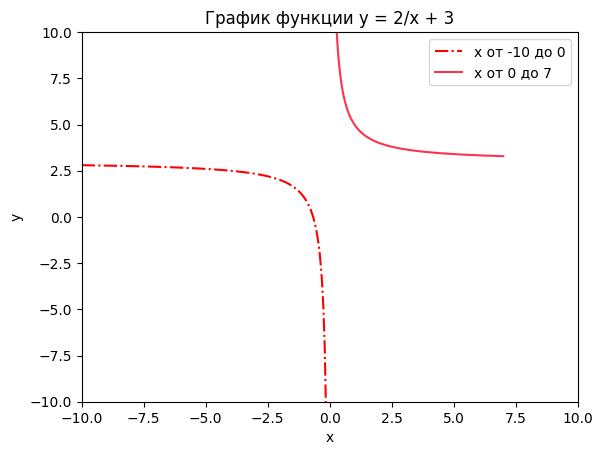

In [ ]:
# Создаём значения x для первого графика
x1 = np.linspace(-10, 0, 200, endpoint=False)

# Создаём значения x для второго графика
x2 = np.linspace(0, 7, 200)[1:]

# Вычисляем y
y1 = 2 / x1 + 3
y2 = 2 / x2 + 3

# Создаём холст и область графика
fig, ax = plt.subplots()

# Рисуем первый график
ax.plot(x1, y1, color='red', linestyle='-.',
        label='x от -10 до 0')

# Рисуем второй график
ax.plot(x2, y2, color=(1.0, 0.2, 0.3), linestyle='-',
        label='x от 0 до 7')

# Настраиваем оси
ax.set_xlim(-10, 10)
ax.set_ylim(-10, 10)

# Подписи и заголовок
ax.set_xlabel('x')
ax.set_ylabel('y')
ax.set_title('График функции y = 2/x + 3')

# Легенда
ax.legend()

plt.show()

Задача **2**

Постройте диаграмму рассеяния для набора данных titanic (файл ./data/titanic.csv).

* По оси X - возврат пассажира (Age)
* По оси Y - стоимость билета (Fare)
* Для выживших пассажиров используется маркер зеленый круг (Survived)
* Для не выживших пассажиров используется маркер красный крест (Survived)
* График должен подписи к осям и легенду и заголовок

Данные для которых не указан возврат или стоимость билета должны быть исключены

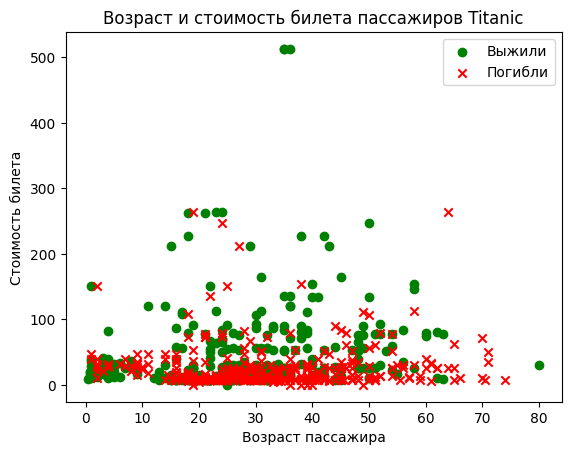

In [ ]:
import pandas as pd

titanic_df = pd.read_csv('/content/titanic.csv')

# Убираем строки, где отсутствует возраст или стоимость билета
data = titanic_df.dropna(subset=['Age', 'Fare'])

# Разделяем пассажиров по результату
rescued = data[data['Survived'] == 1]
deceased = data[data['Survived'] == 0]

fig, ax = plt.subplots()

# Выжившие
ax.scatter(rescued['Age'], rescued['Fare'],
           color='green', marker='o', label='Выжили')

# Погибшие
ax.scatter(deceased['Age'], deceased['Fare'],
           color='red', marker='x', label='Погибли')

ax.set_xlabel('Возраст пассажира')
ax.set_ylabel('Стоимость билета')
ax.set_title('Возраст и стоимость билета пассажиров Titanic')

ax.legend()
plt.show()

Задача **3**

Для первоначального анализа данных часто используются диаграммы рассеяния для всех признаков из набора данных. Это позволяет визуально увидеть зависимости между признаками и выбросы.
Для набора данных [iris](https://ru.wikipedia.org/wiki/%D0%98%D1%80%D0%B8%D1%81%D1%8B_%D0%A4%D0%B8%D1%88%D0%B5%D1%80%D0%B0) постройте на одном холсте 16 диаграмм рассеяния показывающих зависимости между всеми признаками набора ('sepal length (cm)','sepal width (cm)','petal length (cm)','petal width (cm)')

* Холст должен содержать 16 графиков на отдельных осях (см. иллюстрацию к статье в Википедия)
* Цвет маркеров должен зависеть от вида ирисов (iris.target)
* Графики должны иметь подписи к осям, легенду и общий заголовок

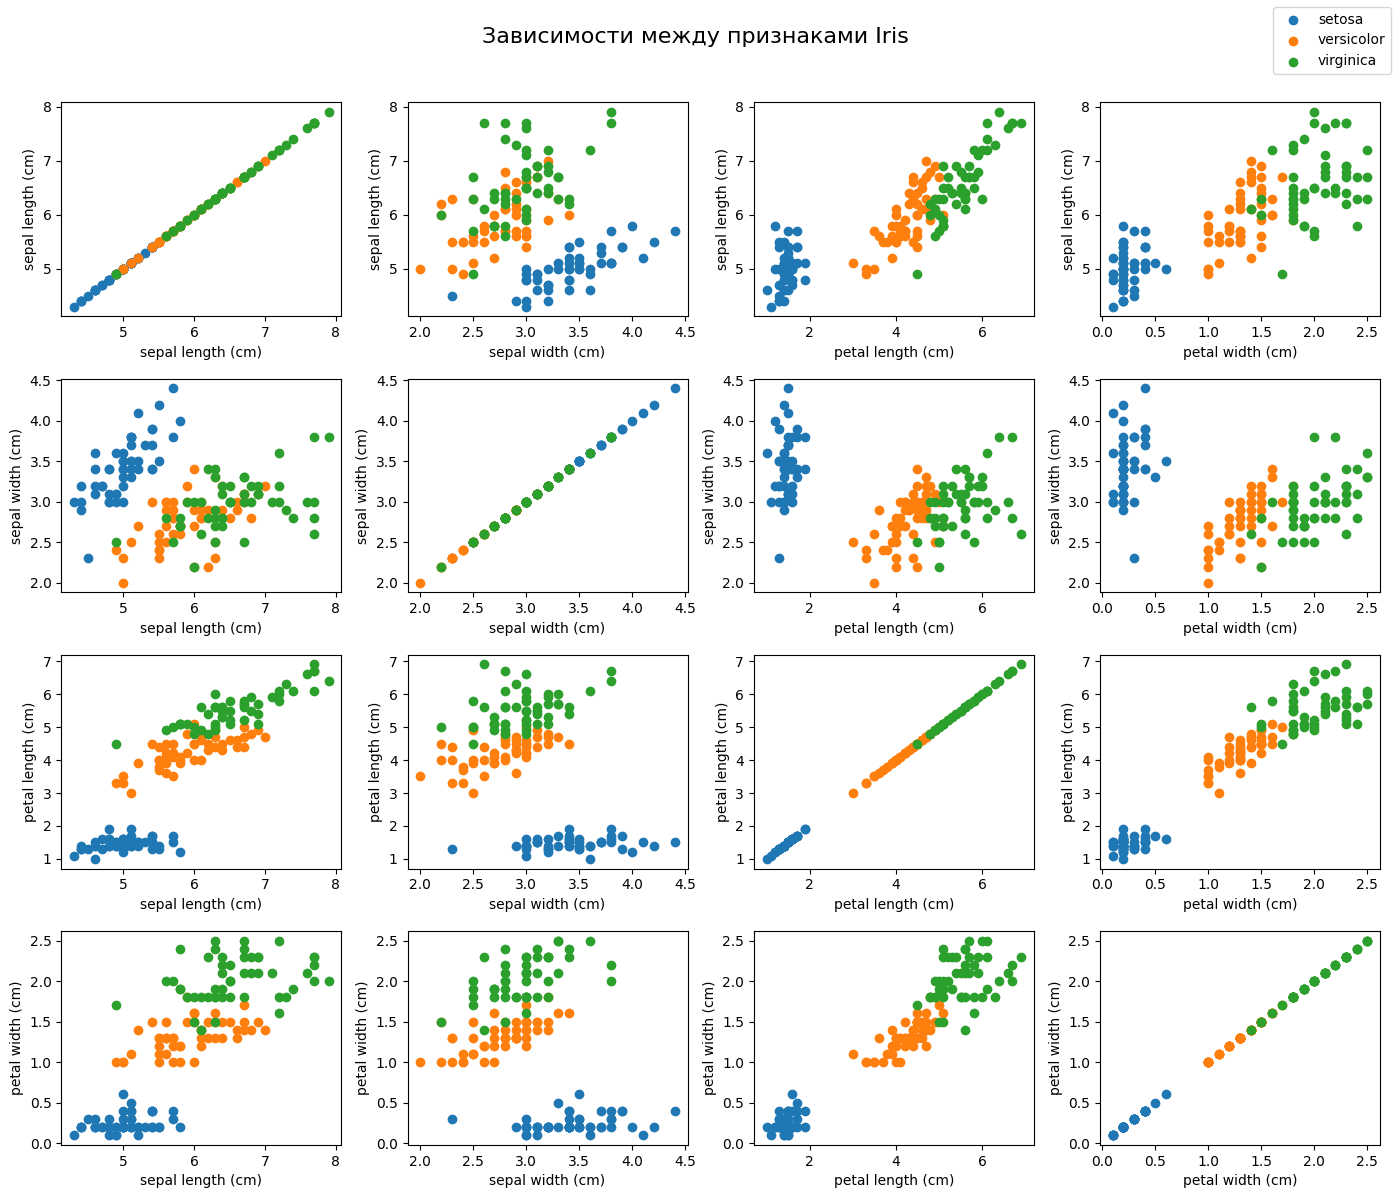

In [ ]:
from sklearn.datasets import load_iris

iris = load_iris()

X = iris.data
y = iris.target
features = iris.feature_names

fig, axes = plt.subplots(4, 4, figsize=(14, 12))

for i in range(4):
    for j in range(4):
        ax = axes[i, j]

        for species in range(3):
            mask = y == species

            ax.scatter(
                X[mask, j],
                X[mask, i],
                label=iris.target_names[species]
            )

        ax.set_xlabel(features[j])
        ax.set_ylabel(features[i])

# Добавляем общий заголовок
fig.suptitle('Зависимости между признаками Iris', fontsize=16)

# Оставляем место для общего заголовка
plt.tight_layout(rect=[0, 0, 1, 0.96])

# Добавляем общую легенду
handles, labels = axes[0, 0].get_legend_handles_labels()
fig.legend(handles, labels, loc='upper right')

plt.show()

Задача **4**

Постройте на одном холсте и разный осях следующие распределения для набора данных titanic (./data/titanic.csv):

* Постройте гистограмму распределения пассажиров по возрасту (Age). Интервал 5 лет.
* Постройте гистограмму распределения пассажиров женского пола по стоимости билетов (Fare). Подберите удобный интервал
* График должен иметь подписи к осям, легенду и заголовок

Данные для которых не указан возраст или стоимость билета должны быть исключены

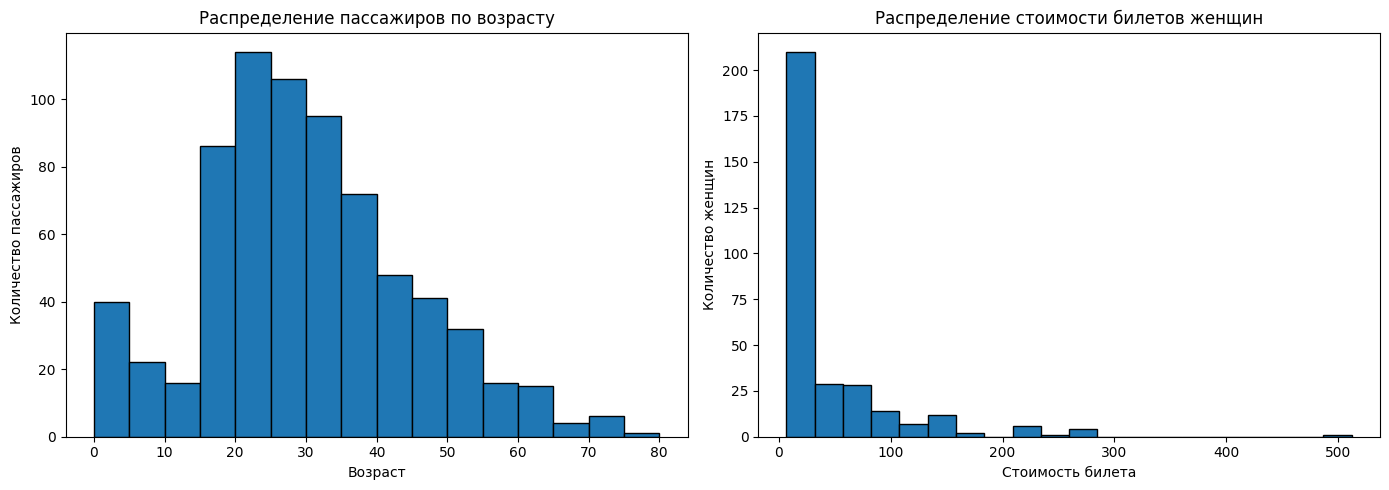

In [ ]:
import pandas as pd

titanic_df = pd.read_csv('/content/titanic.csv')

# Оставляем строки с известным возрастом
ages = titanic_df['Age'].dropna()

# Оставляем женщин с известной стоимостью билета
female_fares = titanic_df.loc[
    (titanic_df['Sex'] == 'female') & titanic_df['Fare'].notna(),
    'Fare'
]

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Первая гистограмма: возраст
age_bins = np.arange(0, ages.max() + 5, 5)

axes[0].hist(ages, bins=age_bins, edgecolor='black')
axes[0].set_xlabel('Возраст')
axes[0].set_ylabel('Количество пассажиров')
axes[0].set_title('Распределение пассажиров по возрасту')

# Вторая гистограмма: стоимость билетов женщин
axes[1].hist(female_fares, bins=20, edgecolor='black')
axes[1].set_xlabel('Стоимость билета')
axes[1].set_ylabel('Количество женщин')
axes[1].set_title('Распределение стоимости билетов женщин')

plt.tight_layout()
plt.show()

Задача **5**

Для набора данных для набора данных titanic (./data/titanic.csv) постройте следующую столбчатую диаграмму:

* Диаграмма должна быть вертикальной
* По оси X - класс каюты пассажира (Pclass)
* По оси Y - средняя стоимость за проезд для данного класса (Fare)
* График должен иметь подписи к осям, легенду и заголовок

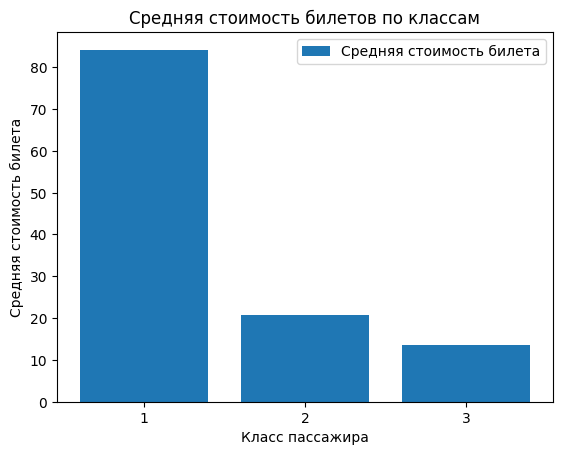

In [2]:
import pandas as pd

titanic_df = pd.read_csv('/content/titanic.csv')

# Средняя стоимость билета в каждом классе
mean_fare = titanic_df.groupby('Pclass')['Fare'].mean()

fig, ax = plt.subplots()

ax.bar(
    mean_fare.index,
    mean_fare.values,
    label='Средняя стоимость билета'
)

ax.set_xlabel('Класс пассажира')
ax.set_ylabel('Средняя стоимость билета')
ax.set_title('Средняя стоимость билетов по классам')

ax.set_xticks([1, 2, 3])
ax.legend()

plt.show()

Задача **6**

Для набора данных для набора данных titanic (./data/titanic.csv) постройте следующую столбчатую диаграмму c накоплением:

* Диаграмма должна быть вертикальной
* По оси X - класс каюты пассажира (Pclass)
* По оси Y - количество пассажиров с разбивкой по полу (Sex)
* График должен иметь подписи к осям, легенду и заголовок

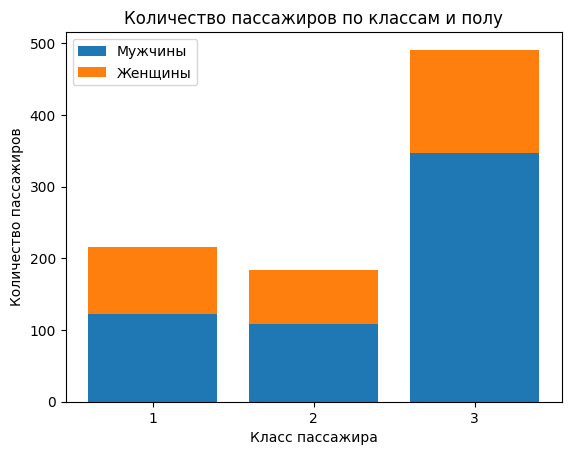

In [3]:
import pandas as pd

titanic_df = pd.read_csv('/content/titanic.csv')

# Подсчитываем количество мужчин и женщин в каждом классе
counts = pd.crosstab(titanic_df['Pclass'], titanic_df['Sex'])

fig, ax = plt.subplots()

ax.bar(
    counts.index,
    counts['male'],
    label='Мужчины'
)

ax.bar(
    counts.index,
    counts['female'],
    bottom=counts['male'],
    label='Женщины'
)

ax.set_xlabel('Класс пассажира')
ax.set_ylabel('Количество пассажиров')
ax.set_title('Количество пассажиров по классам и полу')

ax.set_xticks([1, 2, 3])
ax.legend()

plt.show()

Задача **7**

Для набора данных iris постройте круговую диаграмму

* Диаграмма должна иметь 3 сектора отражающих долю ирисов данного вида в наборе
* Сектор с максимальной долей долен быть выдвинут
* График должен иметь подписи к осям, легенду и заголовок

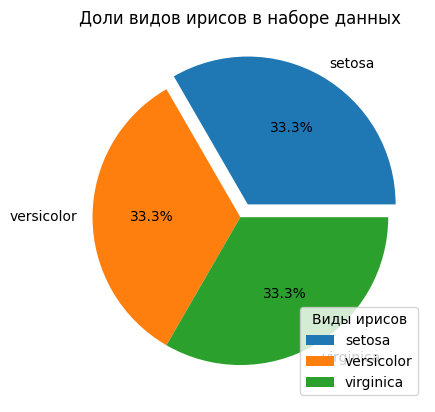

In [4]:
from sklearn.datasets import load_iris
iris = load_iris()

#Считаем количество цветков каждого вида
counts = np.bincount(iris.target)

# Находим индекс вида с максимальным количеством
largest = np.argmax(counts)

# Выдвигаем самый большой сектор
explode = [0, 0, 0]
explode[largest] = 0.1

fig, ax = plt.subplots()

ax.pie(
    counts,
    labels=iris.target_names,
    autopct='%1.1f%%',
    explode=explode
)

ax.set_title('Доли видов ирисов в наборе данных')
ax.legend(iris.target_names, title='Виды ирисов')

plt.show()

Задача **10**

Использую библиотеку [Seaborn](https://seaborn.pydata.org/) постройте гистограмму для возраста пассажиров "Титаника"

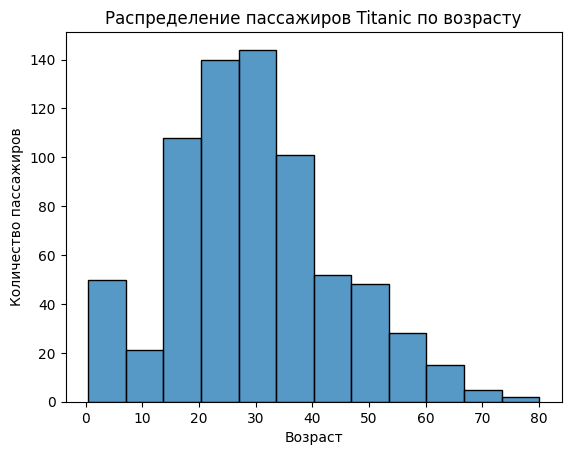

In [8]:
import seaborn as sns
import pandas as pd

titanic_df = pd.read_csv('/content/titanic.csv')

fig, ax = plt.subplots()

sns.histplot(
    data=titanic_df,
    x='Age',
    bins=12,
    ax=ax
)

ax.set_xlabel('Возраст')
ax.set_ylabel('Количество пассажиров')
ax.set_title('Распределение пассажиров Titanic по возрасту')

plt.show()


## Вопросы


1. Для чего используется диаграмма рассеяния?
Диаграмма рассеяния (scatter plot) используется для визуального исследования связи между двумя числовыми признаками. Каждая точка представляет отдельное наблюдение. По графику можно увидеть тенденции, группы объектов и выбросы.


2. Что такое гистограмма и чем она отличается от столбчатой диаграммы?
Гистограмма показывает распределение числовых данных по интервалам. Столбцы соответствуют диапазонам числовых значений.

Столбчатая диаграмма сравнивает значения отдельных категорий, например количество пассажиров в каждом классе.

Главное отличие: гистограмма обычно показывает распределение непрерывных числовых данных, а столбчатая диаграмма — сравнение категорий.


3. Как задать цвет линии в линейном графике Matplotlib?
С помощью параметра color:
`plt.plot(x, y, color='red')`


Можно также использовать RGB-кортеж:
`plt.plot(x, y, color=(1.0, 0.2, 0.3))`


4. Чем Figure отличается от Axes?
Figure — весь холст, на котором размещаются графики.

Axes — отдельная область графика с осями, данными, заголовком и подписями.

Один объект Figure может содержать несколько объектов Axes.


5. Matplotlib не позволяет управлять типом маркера scatter-графика. Да или нет?
Нет, это утверждение неверно.

Тип маркера можно задавать параметром marker:
`plt.scatter(x, y, marker='x')`


6. Matplotlib — единственная библиотека для построения графиков в Python. Да или нет?
Нет.

Существуют и другие библиотеки, например Seaborn, Plotly, Bokeh и Altair.
7. Matplotlib не позволяет сохранить график в виде файла, нужно делать скриншот?
Нет, это утверждение неверно.

График можно сохранить с помощью savefig():
`plt.savefig('graph.png')`


Например, можно сохранить изображение в формате PNG или PDF:
`plt.savefig('graph.png', dpi=300, bbox_inches='tight')plt.savefig('graph.pdf', bbox_inches='tight')`


8. В наборе данных Iris представлены четыре вида ирисов. Да или нет?
Нет.

В стандартном наборе Iris представлены три вида:
- setosa;
- versicolor;
- virginica.
При этом у каждого цветка есть четыре числовых признака.


9. Для всех пассажиров Titanic указан возраст. Да или нет?
Нет.

В стандартном наборе Titanic есть пропущенные значения в столбце Age. Поэтому при построении графиков и вычислении статистик нужно учитывать пропуски.
10. На одном холсте может располагаться не более 16 диаграмм, потому что размер диаграммы нельзя изменить. Да или нет?
Нет.

Количество областей графика не ограничено числом 16. Можно создать, например, 20 областей:
fig, axes = plt.subplots(4, 5, figsize=(16, 12))


Это будет холст с 20 графиками: 4 строки и 5 столбцов.

Размер холста можно менять с помощью figsize. Однако если графиков слишком много, их подписи и данные могут стать трудночитаемыми.